# AI SCI 290A Project 1: Weather Prediction
Using ERA5 data to answer the question Can we predict the weather at UC Irvine?

# 1. Imports

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns
import glob
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import mean_squared_error, auc, roc_curve

from sklearn.preprocessing import StandardScaler

# 2. Preliminary Exploration

In [41]:
DATA_DIR = "./data/"

In [42]:
temp_files = sorted(
    glob.glob(f"{DATA_DIR}/**/*.nc", recursive=True)
)
ds = xr.open_mfdataset(
    temp_files,
    combine="by_coords"
)

## Avg temp

Text(0.5, 1.0, 'Mean 2m temp')

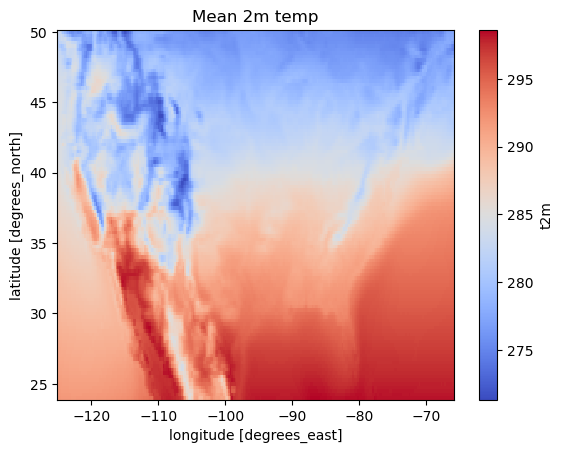

In [43]:
fig, ax = plt.subplots()
ds.t2m.mean(dim="valid_time").plot(cmap="coolwarm")
ax.set_title("Mean 2m temp")

In [44]:
ds["t2m"] = ds["t2m"]-273.15

## Temperature over time at UC Irvine

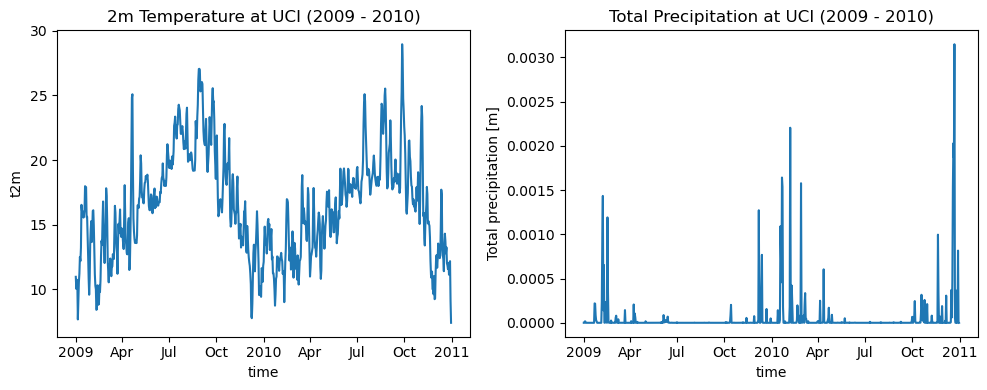

In [45]:
lat_uci, lon_uci = 33.64, -117.84

ds_uci = ds.sel(latitude=lat_uci, longitude=lon_uci, method="nearest")

fig, axs = plt.subplots(
    ncols=2,
    figsize=(10, 4)
)
ds_uci.t2m.plot(ax=axs[0])
axs[0].set_title("2m Temperature at UCI (2009 - 2010)")

ds_uci.tp.plot(ax=axs[1])
axs[1].set_title("Total Precipitation at UCI (2009 - 2010)")

fig.tight_layout()

## Feature Engineering

In [46]:
# Calcs and adds 3 and 7 day rolling average and previous day columns
ds_uci['rolling_3'] = ds_uci['t2m'].rolling(valid_time=3).mean() 
ds_uci['rolling_7'] = ds_uci['t2m'].rolling(valid_time=7).mean()
ds_uci["target_t2m"] = ds_uci["t2m"].shift(valid_time=-3) # target 3 days in the future

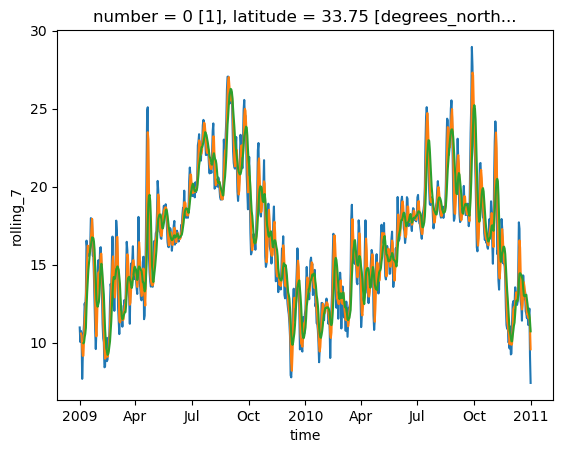

In [47]:
fig, ax = plt.subplots()

ds_uci["t2m"].plot()
ds_uci["rolling_3"].plot()
ds_uci["rolling_7"].plot()

# 3. Temperature

In [48]:
# Prep for regression by deleting nan rows
ds_uci = ds_uci.dropna(dim="valid_time")

# Test train split
X = ds_uci.to_dataframe()[["t2m", "rolling_3", "rolling_7"]]
y = ds_uci["target_t2m"].values

X_train, X_split, y_train, y_split = train_test_split(X, y, random_state=210, shuffle=False, test_size=0.5)

X_val, X_test, y_val, y_test = train_test_split(X_split, y_split, random_state=210, shuffle=False, test_size=0.5)


In [49]:
# Data rescaling

X_scaler = StandardScaler().fit(X_train)

X_train_sc = X_scaler.transform(X_train)
X_val_sc = X_scaler.transform(X_val)
X_test_sc = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_clean = y_train.reshape(-1, 1)

y_scaler.fit(y_train_clean)
y_train_sc = y_scaler.transform(y_train_clean)
y_val_sc = y_scaler.transform(y_val.reshape(-1, 1))
y_test_sc = y_scaler.transform(y_test.reshape(-1, 1))

In [50]:
# Set up metrics
train_mse = pd.DataFrame(columns=["model", "score", "mse"])
val_mse = pd.DataFrame(columns=["model", "score", "mse"])

## Linear Regression
Predicts 3 days in the future using a 3-day rolling average, 7-day rolling average, today's temperature.

### Predictors: Previous Day, 3-Day Rolling, and 7-Day Rolling

In [51]:
reg = LinearRegression()
reg.fit(X_train, y_train)

y_pred = reg.predict(X_train)

train_mse.loc[len(train_mse)] = {
    'model': 'linear_reg_3', 
    'score': reg.score(X_train, y_train), 
    'mse': mean_squared_error(y_train, y_pred)
    }

y_pred = reg.predict(X_val)

val_mse.loc[len(val_mse)] = {
    'model': 'linear_reg_3', 
    'score': reg.score(X_val, y_val), 
    'mse': mean_squared_error(y_val, y_pred)
    }

## Neural Network - 3 var

In [52]:
import copy

import torch
import torch.nn as nn
from sklearn.metrics import r2_score
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(222)

class TempNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout_rate=0.2):
        super(TempNN, self).__init__()
        
        # Structural layers
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden_dim, output_dim)
        
    def forward(self, x):
        # Process the forward pass step-by-step
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [53]:
def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val, 
    criterion=nn.MSELoss(),
    epochs=300,
    batch_size=32,
    lr=1e-3,
    patience=25,
    lr_decay=1.0,
):
    """Train a regression network and restore the weights with the best validation loss."""

    def as_batch(features, labels):
        x = torch.as_tensor(np.asarray(features), dtype=torch.float32)
        y = torch.as_tensor(np.asarray(labels), dtype=torch.float32)
        if x.ndim == 2:
            x = x.unsqueeze(1)  # (samples, 1, features) for the LSTM
        if y.ndim == 1:
            y = y.unsqueeze(-1)
        return x, y

    X_tr, y_tr = as_batch(X_train, y_train)
    X_va, y_va = as_batch(X_val, y_val)
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)

    criterion = criterion
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=lr_decay)

    best_state = copy.deepcopy(model.state_dict())
    best_val = float("inf")
    wait = 0
    stopped = epochs

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_va), y_va).item()
        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                stopped = epoch
                break
        scheduler.step()

    model.load_state_dict(best_state)
    model.eval()
    return model, stopped

In [54]:
model = TempNN(input_dim=X_train_sc.shape[1], hidden_dim=128, output_dim=1)

model, epoch = train_model(model, X_train_sc, y_train_sc, X_val_sc, y_val_sc)

In [55]:
model.eval()
with torch.no_grad():
    pred_tr = model(torch.as_tensor(X_train_sc, dtype=torch.float32)).numpy()
    pred_va = model(torch.as_tensor(X_val_sc, dtype=torch.float32)).numpy()

pred_tr = y_scaler.inverse_transform(pred_tr).ravel()
pred_va = y_scaler.inverse_transform(pred_va).ravel()

train_mse.loc[len(train_mse)] = {
    "model": "nn_3",
    "score": r2_score(y_train, pred_tr),
    "mse": mean_squared_error(y_train, pred_tr),
}
val_mse.loc[len(val_mse)] = {
    "model": "nn_3",
    "score": r2_score(y_val, pred_va),
    "mse": mean_squared_error(y_val, pred_va),
}

## Neural Network - all var

In [56]:
X = ds_uci.to_dataframe()[["t2m", "rolling_3", "rolling_7", "u10", "v10", "msl", "tp"]]

X_train, X_split, y_train, y_split = train_test_split(X, y, random_state=222, shuffle=False, test_size=0.5)
X_val, X_test, y_val, y_test = train_test_split(X_split, y_split, random_state=222, shuffle=False, test_size=0.5)

# Data rescaling

X_scaler = StandardScaler().fit(X_train)

X_train_sc = X_scaler.transform(X_train)
X_val_sc = X_scaler.transform(X_val)
X_test_sc = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_clean = y_train.reshape(-1, 1)

y_scaler.fit(y_train_clean)
y_train_sc = y_scaler.transform(y_train_clean)
y_val_sc = y_scaler.transform(y_val.reshape(-1, 1))
y_test_sc = y_scaler.transform(y_test.reshape(-1, 1))

In [57]:
model = TempNN(input_dim=X_train_sc.shape[1], hidden_dim=128, output_dim=1)

model, epoch = train_model(model, X_train_sc, y_train_sc, X_val_sc, y_val_sc)

model.eval()
with torch.no_grad():
    pred_tr = model(torch.as_tensor(X_train_sc, dtype=torch.float32)).numpy()
    pred_va = model(torch.as_tensor(X_val_sc, dtype=torch.float32)).numpy()

pred_tr = y_scaler.inverse_transform(pred_tr).ravel()
pred_va = y_scaler.inverse_transform(pred_va).ravel()

train_mse.loc[len(train_mse)] = {
    "model": "nn_7",
    "score": r2_score(y_train, pred_tr),
    "mse": mean_squared_error(y_train, pred_tr),
}
val_mse.loc[len(val_mse)] = {
    "model": "nn_7",
    "score": r2_score(y_val, pred_va),
    "mse": mean_squared_error(y_val, pred_va),
}

## LSTM - 7-day sequence
Each sample is the previous 7 days of temperature, wind, pressure, and precipitation. The target is still the temperature 3 days ahead.

In [58]:
torch.manual_seed(222)

class TemperatureLSTM(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=32, num_layers=1, output_dim=1):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

def to_sequence(features, labels):
    # One day per sample, three features. Shape (samples, 1, 3).
    x = torch.from_numpy(np.asarray(features, dtype=np.float32)).unsqueeze(1)
    y_tensor = torch.from_numpy(np.asarray(labels, dtype=np.float32))
    return x, y_tensor

def make_windows(features, labels, history):
    """Stack the previous `history` days into each sample.

    Sample t uses days [t - history + 1, t] and the label already stored on day t.
    """
    features = np.asarray(features)
    labels = np.asarray(labels)
    xs = [
        features[t - history + 1 : t + 1]
        for t in range(history - 1, len(features))
    ]
    ys = [labels[t] for t in range(history - 1, len(labels))]
    return np.stack(xs), np.asarray(ys)

In [59]:
feature_cols = ["t2m", "u10", "v10", "msl", "tp"]

X = ds_uci.to_dataframe()[feature_cols]
y = ds_uci["target_t2m"].values

X_train, X_split, y_train, y_split = train_test_split(
    X, y, random_state=210, shuffle=False, test_size=0.5
)
X_val, X_test, y_val, y_test = train_test_split(
    X_split, y_split, random_state=210, shuffle=False, test_size=0.5
)

X_scaler = StandardScaler().fit(X_train)
X_train_sc = X_scaler.transform(X_train)
X_val_sc = X_scaler.transform(X_val)
X_test_sc = X_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train_sc = y_scaler.fit_transform(y_train.reshape(-1, 1))
y_val_sc = y_scaler.transform(y_val.reshape(-1, 1))
y_test_sc = y_scaler.transform(y_test.reshape(-1, 1))

In [60]:
history = 7

Xtr_w, ytr_w = make_windows(X_train_sc, y_train_sc, history)
Xva_w, yva_w = make_windows(X_val_sc, y_val_sc, history)
_, ytr_c = make_windows(X_train_sc, y_train, history)
_, yva_c = make_windows(X_val_sc, y_val, history)

model, epoch = train_model(
    TemperatureLSTM(input_dim=Xtr_w.shape[-1]),
    Xtr_w,
    ytr_w,
    Xva_w,
    yva_w,
)

model.eval()
with torch.no_grad():
    pred_tr = model(torch.as_tensor(Xtr_w, dtype=torch.float32)).numpy()
    pred_va = model(torch.as_tensor(Xva_w, dtype=torch.float32)).numpy()

pred_tr = y_scaler.inverse_transform(pred_tr).ravel()
pred_va = y_scaler.inverse_transform(pred_va).ravel()

train_mse.loc[len(train_mse)] = {
    "model": "lstm_seq",
    "score": r2_score(ytr_c, pred_tr),
    "mse": mean_squared_error(ytr_c, pred_tr),
}
val_mse.loc[len(val_mse)] = {
    "model": "lstm_seq",
    "score": r2_score(yva_c, pred_va),
    "mse": mean_squared_error(yva_c, pred_va),
}

print(f"input shape {Xtr_w.shape}")
print(f"stopped after epoch {epoch}")
print(
    f"LSTM seq  R² {r2_score(yva_c, pred_va):.3f}   "
    f"MSE {mean_squared_error(yva_c, pred_va):.3f}"
)

input shape (354, 7, 5)
stopped after epoch 39
LSTM seq  R² 0.592   MSE 2.666


## Metrics and Comparison

In [61]:
val_mse

,model,score,mse
0,linear_reg_3,0.428962,3.630628
1,nn_3,0.477416,3.322561
2,nn_7,0.477716,3.320657
3,lstm_seq,0.591781,2.665557


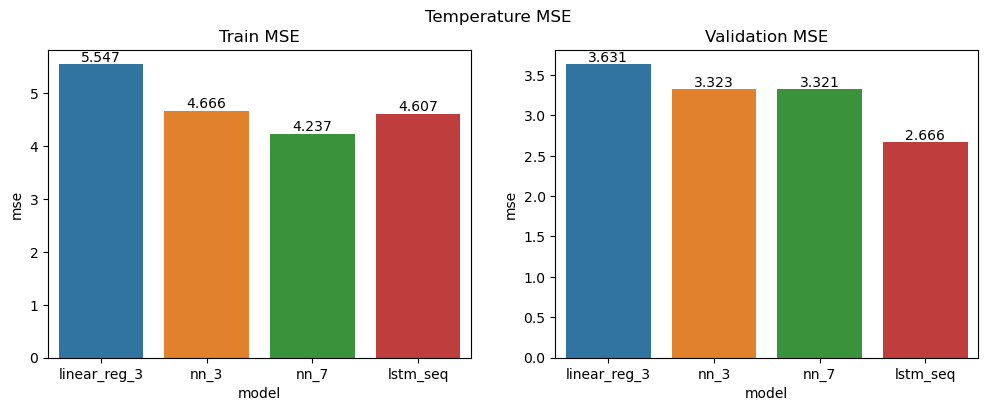

In [62]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

fig.suptitle("Temperature MSE")
ax[0].set_title("Train MSE")
ax[1].set_title("Validation MSE")
sns.barplot(data=train_mse, x="model", y="mse", hue="model", ax=ax[0])
sns.barplot(data=val_mse, x="model", y="mse", hue="model", ax=ax[1])
for n in range(2):
    for container in ax[n].containers:
        ax[n].bar_label(container, fmt='%.3f', padding=0)


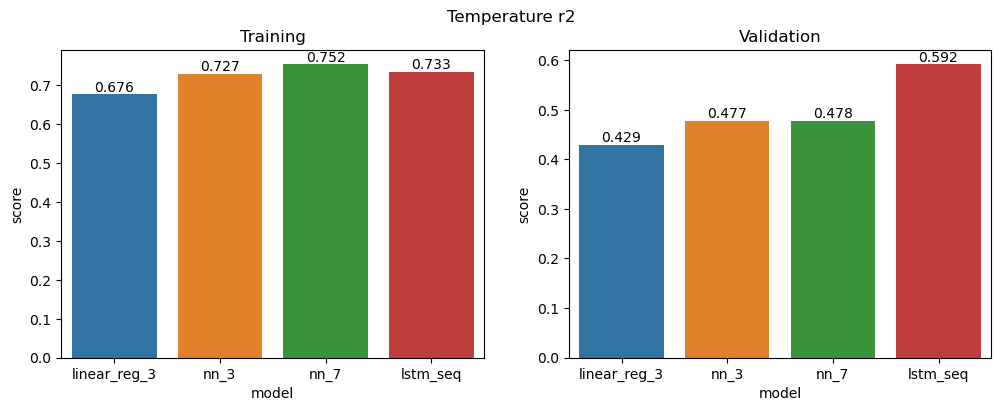

In [63]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

fig.suptitle("Temperature r2")
ax[0].set_title("Training")
ax[1].set_title("Validation")
sns.barplot(data=train_mse, x="model", y="score", hue="model", ax=ax[0])
sns.barplot(data=val_mse, x="model", y="score", hue="model", ax=ax[1])
for n in range(2):
    for container in ax[n].containers:
        ax[n].bar_label(container, fmt='%.3f', padding=0)